In [2]:
import pandas as pd

In [3]:
# ler o arquivo dados.xlsx

df1 = pd.read_excel('/content/dados.xlsx', sheet_name='Por Canal')

df1.head()


,Estabelecimento,Data,Dia,Modo,Integração,Tabela Preço,N.Pessoas
0,JAPPA DA QUITANDA - ANÁLIA FRANCO,2025-08-01,Sexta,Salão,0,0,201
1,JAPPA DA QUITANDA - ANÁLIA FRANCO,2025-08-02,Sábado,Salão,0,0,266
2,JAPPA DA QUITANDA - ANÁLIA FRANCO,2025-08-03,Domingo,Salão,0,0,234
3,JAPPA DA QUITANDA - ANÁLIA FRANCO,2025-08-04,Segunda,Salão,0,0,231
4,JAPPA DA QUITANDA - ANÁLIA FRANCO,2025-08-05,Terça,Salão,0,0,213


"Por canal" e "Consumo de Produtos" são as abas da planilha que estamos trabalhando.<br>
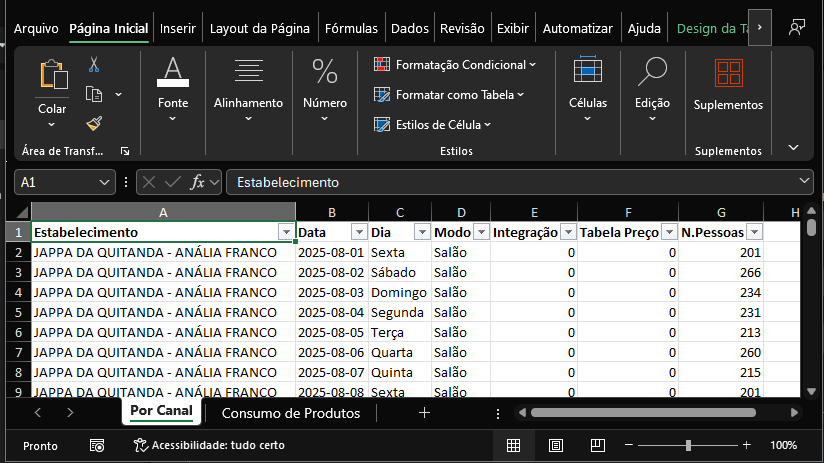

In [4]:
df2 = pd.read_excel('/content/dados.xlsx', sheet_name='Consumo de Produtos')

df2.head()


,Estabelecimento,Cod.,Categoria,Descrição,Quant.,T. Categoria
0,JAPPA DA QUITANDA - ANÁLIA FRANCO,2000,RENTRADA,R SUNOMONO,0,RODIZIO
1,JAPPA DA QUITANDA - ANÁLIA FRANCO,2001,RENTRADA,R CAMARAO CATUPIRY,0,RODIZIO
2,JAPPA DA QUITANDA - ANÁLIA FRANCO,2002,RENTRADA,R CROQUETA SALMAO TERIYAKI,0,RODIZIO
3,JAPPA DA QUITANDA - ANÁLIA FRANCO,2003,R PRATOS QUENTES,R MIX DE COGUMELOS,0,RODIZIO
4,JAPPA DA QUITANDA - ANÁLIA FRANCO,2004,RENTRADA,R TEMPURA LEGUMES,0,RODIZIO


In [13]:
# filtrar categorias desejadas, no caso, T. Categoria
df2 = df2[df2['T. Categoria'].isin(['DRINKS', 'SOFT DRINKS'])] # dentro de T. Categoria, eu quero apenas DRINKS E SOFT DRINKS
df2.head(15)

,Estabelecimento,Cod.,Categoria,Descrição,Quant.,T. Categoria
158,JAPPA DA QUITANDA - ANÁLIA FRANCO,3103,SOFT DRINKS,AGUA COM GAS,267,SOFT DRINKS
159,JAPPA DA QUITANDA - ANÁLIA FRANCO,3104,SOFT DRINKS,AGUA SEM GAS,318,SOFT DRINKS
160,JAPPA DA QUITANDA - ANÁLIA FRANCO,3105,SOFT DRINKS,COCA COLA,272,SOFT DRINKS
161,JAPPA DA QUITANDA - ANÁLIA FRANCO,3106,SOFT DRINKS,COCA COLA ZERO,281,SOFT DRINKS
162,JAPPA DA QUITANDA - ANÁLIA FRANCO,3107,SOFT DRINKS,GUARANA ANTARCTICA,257,SOFT DRINKS
163,JAPPA DA QUITANDA - ANÁLIA FRANCO,3108,SOFT DRINKS,GUARANA ANTARCTICA ZERO,282,SOFT DRINKS
164,JAPPA DA QUITANDA - ANÁLIA FRANCO,3109,SOFT DRINKS,CAFE DESCAFEINADO,349,SOFT DRINKS
165,JAPPA DA QUITANDA - ANÁLIA FRANCO,3110,SOFT DRINKS,CAFE EXPRESSO,255,SOFT DRINKS
166,JAPPA DA QUITANDA - ANÁLIA FRANCO,3111,SOFT DRINKS,CHA DO JAPPA,319,SOFT DRINKS
167,JAPPA DA QUITANDA - ANÁLIA FRANCO,3112,SOFT DRINKS,MATE DO JAPPA,270,SOFT DRINKS


In [14]:
# agrupando valores (total de clientes atendidos por loja)
n_pessoas = df1.groupby('Estabelecimento')['N.Pessoas'].sum()
n_pessoas.head()

,N.Pessoas
Estabelecimento,
JAPPA DA QUITANDA - ANÁLIA FRANCO,13088
JAPPA DA QUITANDA - BARRA SHOPPING,26563


In [15]:
# calcular quantidades de produtos vendidos por loja e categoria
quant = df2.groupby(['Estabelecimento', 'T. Categoria'])['Quant.'].sum()
quant.head()


Estabelecimento                     T. Categoria
JAPPA DA QUITANDA - ANÁLIA FRANCO   DRINKS          13428
                                    SOFT DRINKS      9433
JAPPA DA QUITANDA - BARRA SHOPPING  DRINKS           1362
                                    SOFT DRINKS     28408
Name: Quant., dtype: int64

In [16]:
# calcular quantidade de pedidos por cliente. Em média cada cliente pediu 1.02 drinks
# e 0.7 soft drinks em Anália Franco
quant_por_pessoa = quant / n_pessoas
quant_por_pessoa.head()

Estabelecimento                     T. Categoria
JAPPA DA QUITANDA - ANÁLIA FRANCO   DRINKS          1.025978
                                    SOFT DRINKS     0.720737
JAPPA DA QUITANDA - BARRA SHOPPING  DRINKS          0.051274
                                    SOFT DRINKS     1.069458
dtype: float64

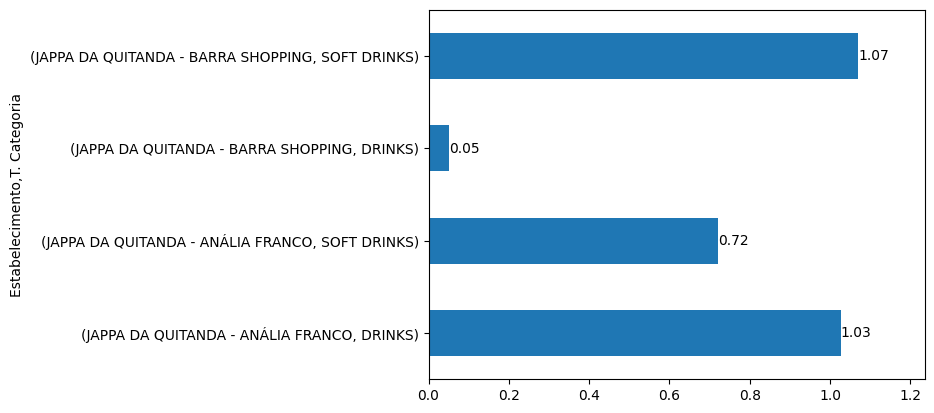

In [24]:
# plotar gráfico para visualizar os resultados
ax = quant_por_pessoa.plot.barh()
ax.bar_label(ax.containers[0], fmt='{:.2f}');
ax.set_xlim(0, ax.get_xlim()[1] * 1.1); # adequando o final da linha p caber tudo


In [30]:
# mostrar top 5 produtos por loja e categoria
top5 = df2.groupby(['Estabelecimento', 'T. Categoria', 'Descrição'])['Quant.'].sum()
top5 = top5.sort_values(ascending=False)
top5 = top5.groupby(['Estabelecimento', 'T. Categoria']).head(5)
top5 = top5.sort_index()
top5.head(10)

Estabelecimento                    T. Categoria  Descrição                              
JAPPA DA QUITANDA - ANÁLIA FRANCO  DRINKS        CARAJILLO 43                                345
                                                 COSMOPOLITAN                                349
                                                 HAKUSHIKA HONJOSO SHU TRADICIONAL 720ML     350
                                                 JIM BEAM                                    346
                                                 MARGARITA                                   344
                                   SOFT DRINKS   CAFE DESCAFEINADO                           349
                                                 MATE DO CHEPH                               681
                                                 MATE MULE                                   333
                                                 SCHWEPPES CITRUS                            595
                                                 SPRITE LEMON FRESH                         1153
Name: Quant., dtype: int64